# Shared experiment workflow

Edit the **STANDARD EXPERIMENT CONTROL** cell, then run the notebook top to bottom. Change `EXPERIMENT_ID` for each run. Try a baseline, remove one feature, adjust one model parameter, or vary `TEST_SIZE`. The examples are commented out; uncomment only the desired entries.

**Evaluation:** For a fair feature/parameter comparison, keep the split and random seed fixed. Changing the split is a separate experiment. The held-out test set is for final assessment, not repeated parameter selection. For daily weather regression, splitting is chronological; for typhoon notebooks, storms/events are kept together to prevent leakage.

**Reporting:** Record experiment ID, removed features, test ratio, parameters, metric, and interpretation. Each run writes a configuration JSON and available result CSV.

In [14]:
# STANDARD EXPERIMENT CONTROL — edit only this cell for normal experiments
EXPERIMENT_ID = "attributes"  # e.g. remove_month_v1, split_30pct_v1
REMOVE_FEATURES = []           # e.g. ["month"] — use actual predictor column names
TEST_SIZE = 0.20               # 0.20=80/20, 0.30=70/30, 0.10=90/10
RANDOM_STATE = 42              # fixed seed makes group splits reproducible

#Example of Model param overrides.
# "Gradient Boosting": {"n_estimators": 300, "learning_rate": 0.03, "max_depth": 4, "subsample": 0.8},
# "HistGradientBoosting": {"max_iter": 300, "max_leaf_nodes": 20, "l2_regularization": 0.1},
# "Multiple Linear Regression": {"fit_intercept": False},
MODEL_PARAM_OVERRIDES = {"HistGradientBoosting": {"max_iter": 300, "max_leaf_nodes": 20, "l2_regularization": 0.1}}
assert 0 < TEST_SIZE < 1, "TEST_SIZE must be between 0 and 1"


# Wind Speed Regression — Model Training and Comparison

This notebook trains and compares three regression models:

1. Multiple Linear Regression
2. Gradient Boosting Regressor
3. HistGradientBoostingRegressor

### Input (X)
- `surface_pressure_mean`
- `surface_pressure_max`
- `surface_pressure_min`
- `pressure_change`
- `wind_direction_10m_dominant`

### Output (y)
- `wind_speed_10m_max` in km/h

The dataset is split chronologically:
- **2023–2025:** training
- **2026:** testing

Evaluation metrics:
- MAE
- RMSE
- R²


In [15]:
from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Resolve project directory.
ROOT = Path.cwd()
if ROOT.name.lower() != "wind":
    if (ROOT / "Wind").exists():
        ROOT = ROOT / "Wind"

DATA_FILE = ROOT / "dataset" / "wind_preprocessed.csv"
MODEL_DIR = ROOT / "trained_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "surface_pressure_mean",
    "surface_pressure_max",
    "surface_pressure_min",
    "pressure_change",
    "wind_direction_10m_dominant",
]

TARGET = "wind_speed_10m_max"


FEATURES = [c for c in FEATURES if c not in REMOVE_FEATURES]
print("Experiment features:", FEATURES)
print("Project root:", ROOT)
print("Dataset:", DATA_FILE)


Experiment features: ['surface_pressure_mean', 'surface_pressure_max', 'surface_pressure_min', 'pressure_change', 'wind_direction_10m_dominant']
Project root: c:\Users\yeesa\OneDrive\Desktop\Group1_COS30049_Computing-Technology-Innovation-main (1)\Group1_COS30049_Computing-Technology-Innovation\Wind
Dataset: c:\Users\yeesa\OneDrive\Desktop\Group1_COS30049_Computing-Technology-Innovation-main (1)\Group1_COS30049_Computing-Technology-Innovation\Wind\dataset\wind_preprocessed.csv


## 1. Load the preprocessed Wind dataset


In [16]:
df = pd.read_csv(DATA_FILE)
df["date"] = pd.to_datetime(df["date"], errors="coerce")

required = ["date"] + FEATURES + [TARGET]
missing = [c for c in required if c not in df.columns]

if missing:
    raise KeyError(f"Missing required columns: {missing}")

for c in FEATURES + [TARGET]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=required).copy()
df = df.sort_values("date").reset_index(drop=True)

print("Rows:", f"{len(df):,}")
print("Date range:", df["date"].min(), "to", df["date"].max())
display(df.head())


Rows: 458,432
Date range: 2021-01-02 00:00:00 to 2026-01-31 00:00:00


,date,prefecture,location_id,town,surface_pressure_mean,surface_pressure_max,surface_pressure_min,pressure_change,wind_direction_10m_dominant,wind_speed_10m_max
0,2021-01-02,Aichi,0,Nagoya,1019.1,1022.0,1016.3,1.5,309,25.9
1,2021-01-02,Oita,0,Oita,1024.2,1026.4,1023.0,0.7,298,18.6
2,2021-01-02,Oita,1,Nakatsu,1024.5,1027.0,1023.1,0.6,264,18.1
3,2021-01-02,Oita,2,Saeki,1024.4,1026.6,1023.0,0.6,303,14.7
4,2021-01-02,Oita,3,Hita,1014.4,1016.6,1012.9,0.7,264,12.1


## 2. Basic Wind Speed Distribution


count    458432.000000
mean         18.671161
std           8.421484
min           2.300000
25%          12.500000
50%          17.000000
75%          23.100000
max         119.300000
Name: wind_speed_10m_max, dtype: float64


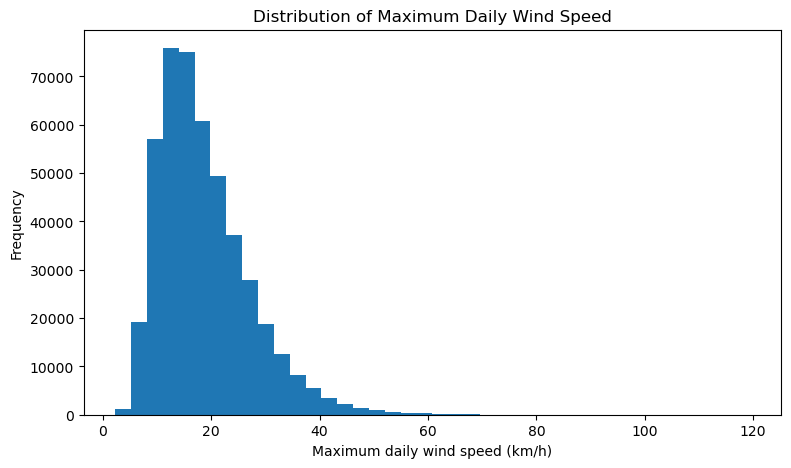

In [17]:
print(df[TARGET].describe())

plt.figure(figsize=(9, 5))
plt.hist(df[TARGET], bins=40)
plt.xlabel("Maximum daily wind speed (km/h)")
plt.ylabel("Frequency")
plt.title("Distribution of Maximum Daily Wind Speed")
plt.show()


## 3. Chronological Train/Test Split


In [18]:
split_at = int(len(df) * (1 - TEST_SIZE))
train = df.iloc[:split_at].copy()
test = df.iloc[split_at:].copy()

if train.empty:
    raise ValueError("Training set is empty.")
if test.empty:
    raise ValueError("Testing set is empty.")

X_train = train[FEATURES]
y_train = train[TARGET]

X_test = test[FEATURES]
y_test = test[TARGET]

print("Training rows:", f"{len(train):,}")
print("Testing rows :", f"{len(test):,}")
print("Training:", train["date"].min(), "to", train["date"].max())
print("Testing :", test["date"].min(), "to", test["date"].max())

train.to_csv(MODEL_DIR / "training.csv", index=False)
test.to_csv(MODEL_DIR / "testing.csv", index=False)

print("Saved training.csv and testing.csv")


Training rows: 366,745
Testing rows : 91,687
Training: 2021-01-02 00:00:00 to 2025-01-25 00:00:00
Testing : 2025-01-25 00:00:00 to 2026-01-31 00:00:00
Saved training.csv and testing.csv


## 4. Define Models

`HistGradientBoostingRegressor` is included as the more computationally efficient
tree-based boosting model for larger datasets.

Random Forest and MARS are not used in this experiment.


In [19]:
models = {
    "Multiple Linear Regression": LinearRegression(),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        learning_rate=0.1,
        max_iter=200,
        max_leaf_nodes=31,
        random_state=42
    ),
}

MODEL_FILES = {
    "Multiple Linear Regression": "multiple_linear_regression.joblib",
    "Gradient Boosting": "gradient_boosting.joblib",
    "HistGradientBoosting": "hist_gradient_boosting.joblib",
}

for name, estimator in models.items():
    if name in MODEL_PARAM_OVERRIDES:
        estimator.set_params(**MODEL_PARAM_OVERRIDES[name])
models


{'Multiple Linear Regression': LinearRegression(),
 'Gradient Boosting': GradientBoostingRegressor(learning_rate=0.05, n_estimators=200, random_state=42),
 'HistGradientBoosting': HistGradientBoostingRegressor(l2_regularization=0.1, max_iter=300,
                               max_leaf_nodes=20, random_state=42)}

## 5. Train, Predict, Evaluate and Save


In [20]:
results = []
predictions = {}

for name, model in models.items():
    print("\n" + "=" * 70)
    print("Training:", name)
    print("=" * 70)

    start = time.time()

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    elapsed = time.time() - start

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    results.append({
        "Model": name,
        "MAE (km/h)": mae,
        "RMSE (km/h)": rmse,
        "R²": r2,
        "Training time (s)": elapsed,
    })

    predictions[name] = pred

    path = MODEL_DIR / MODEL_FILES[name]
    joblib.dump(model, path)

    print(f"MAE : {mae:.4f} km/h")
    print(f"RMSE: {rmse:.4f} km/h")
    print(f"R²  : {r2:.4f}")
    print(f"Time: {elapsed:.2f} seconds")
    print("Saved:", path)

results_df = pd.DataFrame(results).sort_values("RMSE (km/h)").reset_index(drop=True)
results_df.to_csv(MODEL_DIR / "model_results.csv", index=False)

display(results_df)



Training: Multiple Linear Regression
MAE : 6.0328 km/h
RMSE: 7.7507 km/h
R²  : 0.1252
Time: 0.13 seconds
Saved: c:\Users\yeesa\OneDrive\Desktop\Group1_COS30049_Computing-Technology-Innovation-main (1)\Group1_COS30049_Computing-Technology-Innovation\Wind\trained_models\multiple_linear_regression.joblib

Training: Gradient Boosting
MAE : 5.8923 km/h
RMSE: 7.5794 km/h
R²  : 0.1634
Time: 132.68 seconds
Saved: c:\Users\yeesa\OneDrive\Desktop\Group1_COS30049_Computing-Technology-Innovation-main (1)\Group1_COS30049_Computing-Technology-Innovation\Wind\trained_models\gradient_boosting.joblib

Training: HistGradientBoosting
MAE : 5.7927 km/h
RMSE: 7.4749 km/h
R²  : 0.1863
Time: 5.39 seconds
Saved: c:\Users\yeesa\OneDrive\Desktop\Group1_COS30049_Computing-Technology-Innovation-main (1)\Group1_COS30049_Computing-Technology-Innovation\Wind\trained_models\hist_gradient_boosting.joblib


,Model,MAE (km/h),RMSE (km/h),R²,Training time (s)
0,HistGradientBoosting,5.792749,7.474892,0.186330,5.389376
1,Gradient Boosting,5.892311,7.579360,0.163427,132.675678
2,Multiple Linear Regression,6.032796,7.750737,0.125168,0.134219


## 6. Actual vs Predicted


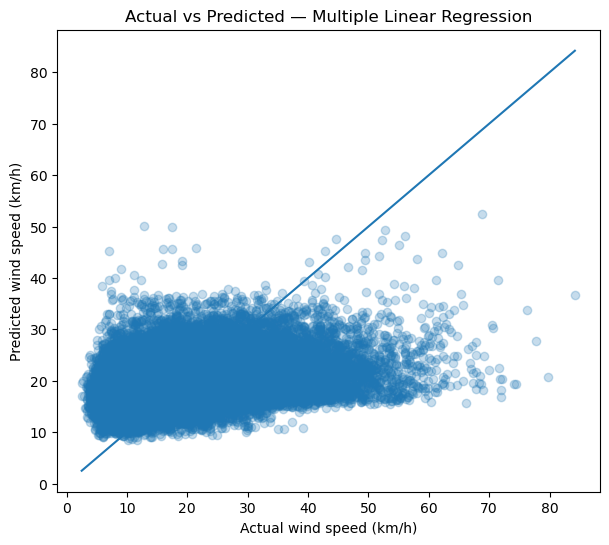

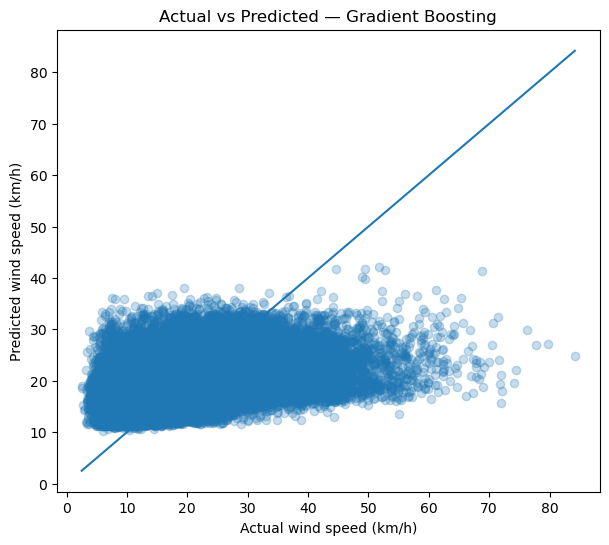

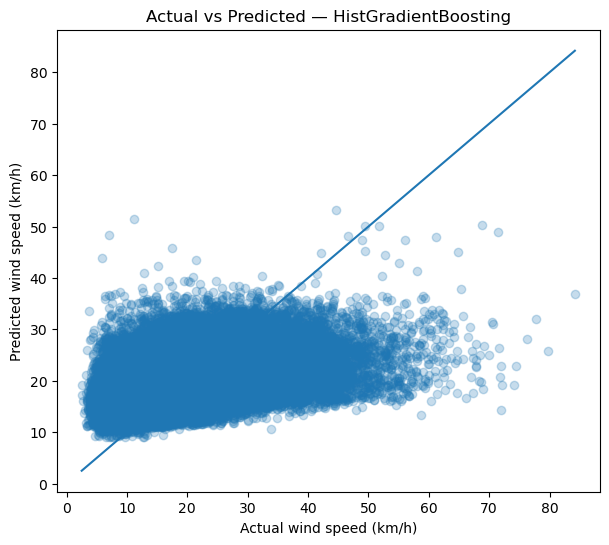

In [21]:
for name, pred in predictions.items():
    plt.figure(figsize=(7, 6))
    plt.scatter(y_test, pred, alpha=0.25)

    low = min(y_test.min(), pred.min())
    high = max(y_test.max(), pred.max())
    plt.plot([low, high], [low, high])

    plt.xlabel("Actual wind speed (km/h)")
    plt.ylabel("Predicted wind speed (km/h)")
    plt.title(f"Actual vs Predicted — {name}")
    plt.show()


## 7. Compare Errors


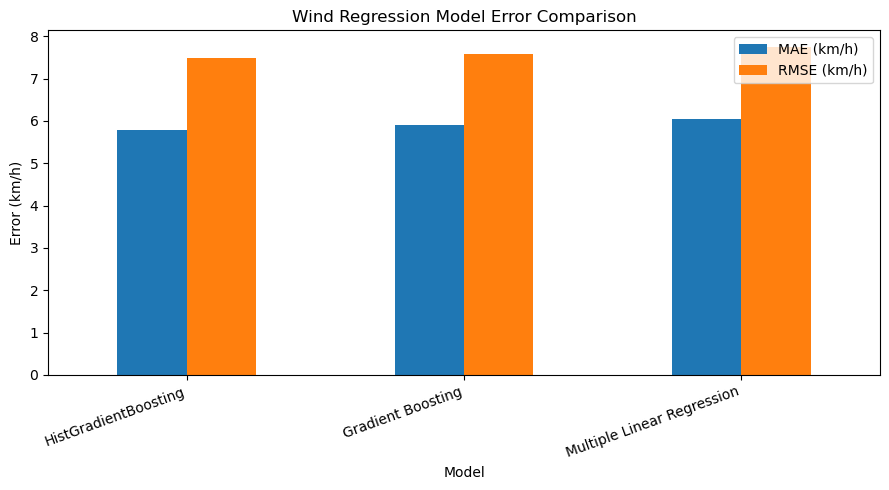

In [22]:
plot_df = results_df.set_index("Model")

plt.figure(figsize=(9, 5))
plot_df[["MAE (km/h)", "RMSE (km/h)"]].plot(kind="bar", ax=plt.gca())
plt.ylabel("Error (km/h)")
plt.title("Wind Regression Model Error Comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


## 8. Multiple Linear Regression Coefficients


In [23]:
mlr = models["Multiple Linear Regression"]

coef_df = pd.DataFrame({
    "Feature": FEATURES,
    "Coefficient": mlr.coef_
}).sort_values("Coefficient", key=abs, ascending=False)

display(coef_df)


,Feature,Coefficient
2,surface_pressure_min,-0.960038
1,surface_pressure_max,0.575014
0,surface_pressure_mean,0.441281
3,pressure_change,0.038668
4,wind_direction_10m_dominant,0.009436


## 9. Final Model Ranking

For **MAE** and **RMSE**, lower is better.

For **R²**, higher is better and values closer to 1 indicate that the model explains
more of the variation in maximum wind speed.

Do not select the final model from training time alone. Compare predictive performance
and computational cost together.


In [24]:
display(
    results_df[
        ["Model", "MAE (km/h)", "RMSE (km/h)", "R²", "Training time (s)"]
    ]
)

best = results_df.iloc[0]
print("Lowest RMSE model:", best["Model"])
print(f'RMSE: {best["RMSE (km/h)"]:.4f} km/h')
print(f'MAE : {best["MAE (km/h)"]:.4f} km/h')
print(f'R²  : {best["R²"]:.4f}')


,Model,MAE (km/h),RMSE (km/h),R²,Training time (s)
0,HistGradientBoosting,5.792749,7.474892,0.186330,5.389376
1,Gradient Boosting,5.892311,7.579360,0.163427,132.675678
2,Multiple Linear Regression,6.032796,7.750737,0.125168,0.134219


Lowest RMSE model: HistGradientBoosting
RMSE: 7.4749 km/h
MAE : 5.7927 km/h
R²  : 0.1863


## Experiment log (run after training)

The CSV and JSON are intended for reporting. This cell does **not** retrain or tune anything. Record the score table above and compare it with earlier runs. Review data leakage and validation methodology before claiming improvements.


In [25]:
from pathlib import Path
import json, datetime
import pandas as pd
experiment_root = Path.cwd() / "experiment_logs" / EXPERIMENT_ID
experiment_root.mkdir(parents=True, exist_ok=True)
active_features = globals().get("FEATURES", globals().get("feature_columns", globals().get("F", [])))
metadata = {"experiment_id": EXPERIMENT_ID, "notebook": "train_wind_models_split", "created_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
 "features": list(active_features), "removed": REMOVE_FEATURES, "test_size": TEST_SIZE, "random_state": RANDOM_STATE, 
 "model_overrides": MODEL_PARAM_OVERRIDES, 
 "note": "Test metrics are descriptive; tune using validation data, not test data."}
(experiment_root / "experiment_config.json").write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")
for key in ("results_df", "results"):
    obj = globals().get(key)
    if isinstance(obj, pd.DataFrame):
        obj.to_csv(experiment_root / "model_comparison.csv", index=False)
        display(obj)
        break
else:
    print("No tabular model comparison found; refer to evaluation outputs above.")
print("Experiment saved to:", experiment_root)
print("Report checklist: model | features | parameter changes | split | validation metric | test metric | training time | interpretation")


,Model,MAE (km/h),RMSE (km/h),R²,Training time (s)
0,HistGradientBoosting,5.792749,7.474892,0.186330,5.389376
1,Gradient Boosting,5.892311,7.579360,0.163427,132.675678
2,Multiple Linear Regression,6.032796,7.750737,0.125168,0.134219


Experiment saved to: c:\Users\yeesa\OneDrive\Desktop\Group1_COS30049_Computing-Technology-Innovation-main (1)\Group1_COS30049_Computing-Technology-Innovation\Wind\experiment_logs\attributes
Report checklist: model | features | parameter changes | split | validation metric | test metric | training time | interpretation
